# Prototype De-stacking

In [1]:
import numpy as np
from matplotlib import pyplot as plt

import glob
import tqdm

#let's use multiprocessing
from multiprocess import Pool, freeze_support, cpu_count
from functools import partial

from colossus.halo import profile_nfw
from colossus.cosmology import cosmology as colossus_cosmology

from scipy import integrate
from scipy.stats import truncnorm
from scipy.stats import norm,multivariate_normal

from nautilus import Prior
from nautilus import Sampler

from astropy.cosmology import FlatLambdaCDM, Planck18 
import astropy.units as u
from astropy import constants
from astropy import table
import galsim

import xlensing
import cluster_toolkit

Lookup tables loaded!


In [ ]:
datadir = "/home/andre/data/TNG_SIMULATED_SHEAR_CATALOGS"

import os
# All simulated per-cluster outputs from this notebook (single_sigmas_*.npy
# etc.) live outside the repo -- moved 2026-07-27, see project memory.
SIM_DATA_DIR = os.path.expanduser("~/destacking_data/sims")
os.makedirs(SIM_DATA_DIR, exist_ok=True)

## Defining Units and scalings between codes

In [3]:
Mhalo = 1e14
conc = 5.
zhalo = .3
zsource = 1.0
OmegaM = 0.3
OmegaL = 0.7
astropy_cosmo = Planck18#FlatLambdaCDM(H0=.7,Om0=OmegaM)
galsim_cosmo = galsim.Cosmology()
halo = galsim.NFWHalo(mass=Mhalo,conc=conc,redshift=zhalo,cosmo=galsim_cosmo)

In [4]:
radii_mpc = np.linspace(0.01,10,1000)
ang_radii = np.degrees(radii_mpc/astropy_cosmo.angular_diameter_distance(.3).value)*3600
positions = [galsim.PositionD(0.,sep) for sep in ang_radii]

In [5]:
shears_galsim = np.array([halo.getShear(position,zsource) for position in positions])

In [6]:
def critical_surface_density(z_l, z_s, cosmo):
    """
    Calculates the critical surface density for gravitational lensing.

    Args:
        z_l (float): Redshift of the lensing galaxy.
        z_s (float): Redshift of the background source.
        cosmo (astropy.cosmology.Cosmology): The cosmological model to use.

    Returns:
        astropy.units.Quantity: The critical surface density.
    """
    # Define angular diameter distances
    D_l = cosmo.angular_diameter_distance(z_l)
    D_s = cosmo.angular_diameter_distance(z_s)
    D_ls = cosmo.angular_diameter_distance_z1z2(z_l, z_s)

    # Formula for the critical surface density
    numerator = (constants.c**2 * D_s)
    denominator = (4 * np.pi * constants.G * D_l * D_ls)
    sigma_crit = numerator / denominator

    # Convert to standard units for surface density (e.g., Msun / sq pc)
    return sigma_crit.to(u.M_sun / u.kpc**2)


# Define the redshifts for the lens and source
z_lens = 0.5   # Example lens redshift
z_source = 2.0 # Example source redshift

# Calculate the critical surface density
sigma_crit_value = critical_surface_density(z_lens, z_source, astropy_cosmo)

print(f"Lens redshift: {z_lens}")
print(f"Source redshift: {z_source}")
print(f"Critical surface density: {sigma_crit_value:.2e}")

# Example comparison: what if the lens is closer?
z_lens_closer = 0.25
sigma_crit_closer = critical_surface_density(z_lens_closer, z_source, astropy_cosmo)

print("\n--- Example with a closer lens ---")
print(f"Lens redshift: {z_lens_closer}")
print(f"Critical surface density: {sigma_crit_closer:.2e}")

Lens redshift: 0.5
Source redshift: 2.0
Critical surface density: 2.02e+09 solMass / kpc2

--- Example with a closer lens ---
Lens redshift: 0.25
Critical surface density: 2.48e+09 solMass / kpc2


In [7]:
def deltasigma_nfw_colossus(colossus_profile,z_source,r):
    z_lens = zhalo
    Sigma_bar = 2*(integrate.quad(lambda r : colossus_profile.surfaceDensity(r)*r,1e-8,r,epsabs=0.,limit=150))[0]/r**2
    Sigma = colossus_profile.surfaceDensity(r)
    deltasigma = Sigma_bar - Sigma
    return deltasigma/1e6

In [8]:
scrit=critical_surface_density(z_l=0.3, z_s=1.0, cosmo=astropy_cosmo).value/1e6

In [9]:
colossus_cosmology.setCosmology('planck18')
colossus_profile=profile_nfw.NFWProfile(M=Mhalo,c=conc,z=zhalo,mdef='200m')
delta_sigma_colossus=np.array([deltasigma_nfw_colossus(colossus_profile,1.,radius*1000) for radius in radii_mpc])

In [10]:
from cluster_toolkit import deltasigma

Sigma_nfw = deltasigma.Sigma_nfw_at_R(radii_mpc, mass=Mhalo, concentration=conc, Omega_m=OmegaM)

delta_sigma_toolkit=deltasigma.DeltaSigma_at_R(
    R=radii_mpc,
    Rs=radii_mpc,
    Sigma=Sigma_nfw,
    mass=Mhalo,
    concentration=conc,
    Omega_m=OmegaM,
    delta=200,
)

In [11]:
delta_sigma_xlensing = xlensing.model.NFW_Delta_Sigma(
    M200m=np.array([Mhalo]),
    C200m=np.array([conc]),
    Z=np.array([zhalo]),
    FMISS=np.array([0.0]),
    SIGMA_OFF=np.array([0.4]),
    BCG_B_MASS=np.array([0.]),
    radii=radii_mpc,
)['NFW Signal']

In [12]:
delta_sigma_galsim = shears_galsim[:,0]*scrit

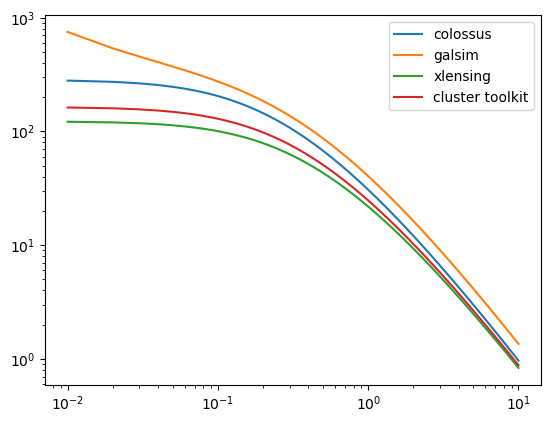

In [13]:
plt.plot(radii_mpc,delta_sigma_colossus,label='colossus')
plt.plot(radii_mpc,delta_sigma_galsim,label='galsim')
plt.plot(radii_mpc,delta_sigma_xlensing[0],label='xlensing')
plt.plot(radii_mpc,delta_sigma_toolkit,label='cluster toolkit')

plt.xscale('log')
plt.yscale('log')
plt.legend()

In [14]:
radii_mpc = np.logspace(-2,1,10)

In [15]:
%%timeit
colossus_profile=profile_nfw.NFWProfile(M=Mhalo,c=conc,z=zhalo,mdef='200m')
delta_sigma_colossus=np.array([deltasigma_nfw_colossus(colossus_profile,1.,radius*1000) for radius in radii_mpc])

31.8 ms ± 646 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [16]:
%%timeit
halo = galsim.NFWHalo(mass=Mhalo,conc=conc,redshift=zhalo,cosmo=galsim_cosmo)
shears_galsim = np.array([halo.getShear(position,zsource) for position in positions])

76.1 ms ± 1.09 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [17]:
%%timeit
xlensing_res=xlensing.model.NFW_Delta_Sigma(np.array([Mhalo]),np.array([conc]),np.array([zhalo]),np.array([0.]),np.array([0.4]),np.array([0.]),radii_mpc)

101 μs ± 8.44 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [18]:
%%timeit
Sigma_nfw = deltasigma.Sigma_nfw_at_R(radii_mpc, mass=Mhalo, concentration=conc, Omega_m=OmegaM)
#shears_toolkit = deltasigma.DeltaSigma_at_R(radii_mpc, Rp, Sigma, Mass, concentartion, Omega_m)
delta_sigma_toolkit=deltasigma.DeltaSigma_at_R(R=radii_mpc,Rs=radii_mpc,Sigma=Sigma_nfw,mass=Mhalo,concentration=conc,Omega_m=OmegaM,delta=200,
)

20.6 μs ± 817 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


## Generating a field of galaxies

In [19]:
n_gal_factor = 100
max_radius = 8
nbar = 30 
cluster = [0.,0.,.3,1e14,5.] 

In [20]:
def simcluster(gal_density,total_radius,z_range,cluster,shape_noise,seed=31415):
    cat = xlensing.sims.make_simple_random_cat(
        density=gal_density, 
        width_rad=total_radius/xlensing.cosmo.DA(0,0.3), 
        zrange=z_range, 
        shape_noise=shape_noise,
        seed=seed
    ).T
    cat = xlensing.sims.apply_NFW_shear_region(cluster,cat)
    cat = table.Table(cat,names=['ra','dec','z','e1','e2','R11','R12','R21','R22','w'])
    return cat 

In [21]:
cluster_test = simcluster(gal_density=nbar,total_radius=max_radius,z_range=[.3,2.],cluster=cluster,shape_noise=0.25/np.sqrt(n_gal_factor),seed=None)

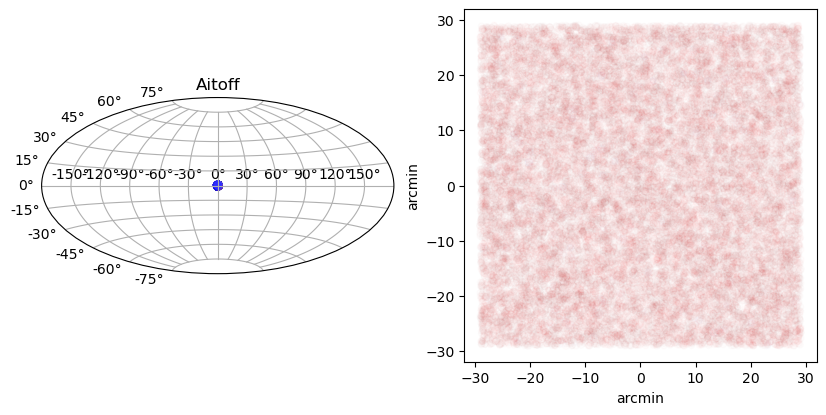

In [22]:
plt.figure(figsize=(10,5))
plt.subplot(121, projection="aitoff")
ellip = np.sqrt(cluster_test['e1']**2+ cluster_test['e2']**2)
plt.scatter(cluster_test['ra'],cluster_test['dec'],s=(cluster_test['z']+1)*10,c=ellip,cmap='seismic')
plt.title("Aitoff")
plt.grid(True)
plt.subplot(122)
plt.scatter(np.degrees(cluster_test['ra'])*60,np.degrees(cluster_test['dec'])*60,s=(cluster_test['z']+1)*10,c=np.log10(ellip),cmap='seismic',alpha=.01)
plt.xlabel('arcmin')
plt.ylabel('arcmin')
ax = plt.gca()
ax.set_aspect('equal')

In [23]:
galaxy_catalog = {}
galaxy_catalog['RA'] = cluster_test['ra']
galaxy_catalog['DEC'] = cluster_test['dec']
galaxy_catalog['ZPHOT'] = cluster_test['z']
galaxy_catalog['E1'] = cluster_test['e1']
galaxy_catalog['E2'] = cluster_test['e2']
galaxy_catalog['WEIGHT'] =  np.ones_like(cluster_test['e1'])
galaxy_catalog['M'] = np.zeros_like(cluster_test['e1'])
galaxy_catalog = table.Table(galaxy_catalog)

## Fitting

In [24]:
clusters = table.Table([[0],[0],[0.3]],names=['RA','DEC', 'Z'])

In [25]:
sr_RA = np.array(galaxy_catalog['RA'])
sr_DEC= np.array(galaxy_catalog['DEC'])
sr_z  = np.array(galaxy_catalog['ZPHOT'])
sr_E1 = np.array(galaxy_catalog['E1'])
sr_E2 = np.array(galaxy_catalog['E2'])
sr_W = np.array(galaxy_catalog['WEIGHT'])
sr_M = np.array(galaxy_catalog['M'])

clusters['INDEX'] = np.array(range(len(clusters)))

In [26]:
galaxy_catalog

RA,DEC,ZPHOT,E1,E2,WEIGHT,M
float64,float64,float64,float64,float64,float64,float64
0.007686343547415013,-0.0038755849772033543,1.9592646089649284,0.019044055388651837,0.05036812832571606,1.0,0.0
0.004929738359802852,0.0005375063102844892,1.9300274061490599,0.047438624232780134,0.04292929425031707,1.0,0.0
0.006676439217107916,-0.003312380493739021,0.9294235132185515,0.005191392166307115,0.000533675531599257,1.0,0.0
-0.002166518599572684,-0.004509815945865442,1.9896122884531606,0.007996529470660185,0.02467330033525171,1.0,0.0
-0.005698893949574589,0.006156602170246427,1.3946349397314095,0.00935466979829756,0.01617045273758971,1.0,0.0
0.0008871531418167562,0.0038961600056132487,1.0495706162193943,0.010301615234283561,-0.008751377300414425,1.0,0.0
0.007373342613337363,-0.0010981962013683587,0.892324914617177,-0.004685346497093273,0.03174430114295093,1.0,0.0
-0.0038118646698730874,-0.006937868402103416,1.2806814232692563,0.0008512888179786582,0.017626372319298526,1.0,0.0
-0.00797275355674848,0.004168474959333602,1.7943016178407103,0.016481050305005705,-0.04279735506409534,1.0,0.0


In [27]:
cl_RA=np.array(clusters['RA'])
cl_DEC= np.array(clusters['DEC'])
cl_z= np.array(clusters['Z'])
cl = np.array([cl_RA,cl_DEC,cl_z]).T

In [28]:
# you can use whatever, but your machine core count is usually a good choice (although maybe not the best)
pool = Pool(cpu_count()) 

#We get a partial function with a constant galaxy catalogue to iterate with clusters.
survey_lensing = partial(
    xlensing.data.lensfit_cluster_lensing,
    sources=(sr_RA, sr_DEC, sr_z, sr_E1, sr_E2, sr_W,sr_M),
    radius=10.
)

In [29]:
clz = zip(cl_RA,cl_DEC,cl_z)
clzlist = [x for x in clz]

In [30]:
results = pool.map(survey_lensing, clzlist)
pool.close()

## Stacking

In [31]:
radii = np.logspace(-.6,.6,8)
N = len(radii)
bins_lims = np.logspace(np.log10(radii[0])+(np.log10(radii[0])-np.log10(radii[1]))/2,
                        np.log10(radii[N-1])-(np.log10(radii[0])-np.log10(radii[1]))/2,N+1)
bins_lims = np.array([[bins_lims[i],bins_lims[i+1]] for i in range(N)])
bins_lims #in Mpc/h

array([[0.2061986 , 0.30599497],
       [0.30599497, 0.45409096],
       [0.45409096, 0.67386272],
       [0.67386272, 1.        ],
       [1.        , 1.48398179],
       [1.48398179, 2.20220195],
       [2.20220195, 3.26802759],
       [3.26802759, 4.84969343]])

In [32]:
stick = [clusters]

In [33]:
Nboot=1000
import time
stick_results = []
for stake in stick:
    t = time.time()
    clusterbkgs = []
    for index in range(1):
        Sigma_crit = np.array(results[0]['Critical Density'])
        e_t = np.array(results[0]['Tangential Shear'])
        e_x = np.array(results[0]['Critical Density'])
        W = np.array(results[0]['Weights'])
        M = np.array(results[0]['Mult. Bias'])
        R = np.array(results[0]['Radial Distance'])
        clusterbkgs.append(np.array([Sigma_crit, e_t, e_x, W, R,M]))
    print(len(clusterbkgs))
    #sigmas, sigmas_cov, xigmas, xigmas_cov = xlensing.data.stack(clusterbkgs,bins_lims,Nboot)
    #stick_results.append( ( sigmas, sigmas_cov, xigmas, xigmas_cov) )
    #print("Done in " + str(time.time()-t) + " seconds.")

1


In [34]:
sigmas, sigmas_cov, xigmas, xigmas_cov = xlensing.data.single_cluster([clusterbkgs[0]],bins_lims,Nboot)

Total galaxies available per bin:
[15, 39, 65, 182, 319, 743, 1642, 3681]

Single cluster:


In [ ]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas),color='red',s=10)
plt.errorbar(radii,np.array(sigmas),
             yerr=np.sqrt(np.diag(sigmas_cov)),
             fmt='.',color='red',markersize=.1,capsize=10,label='data shear')
#plt.xlim([5e-2,4e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')
radii_mpc = np.linspace(0.01,10,1000)
plt.plot(radii_mpc,delta_sigma_toolkit,label='cluster toolkit')
plt.plot(radii_mpc,delta_sigma_xlensing[0],label='xlensing')
plt.legend()
plt.savefig("figs/1clustertest.png")

# Fitting a single cluster

In [ ]:
from scipy.stats import truncnorm

loc = 3
a_trunc = 0.1
b_trunc = 40
scale = 5
a, b = (a_trunc - loc) / scale, (b_trunc - loc) / scale
prior_c= truncnorm(a=a,b=b,loc=loc,scale=scale)


prior = Prior()
prior.add_parameter('logMhalo', dist=norm(12,4))



prior.add_parameter('conc', dist=prior_c)

In [ ]:
def model_wrapper(param_dict):
    delta_sigma_model=xlensing.model.NFW_Delta_Sigma(
        np.array([10**param_dict['logMhalo']]),
        np.array([param_dict['conc']]),
        np.array([zhalo]),
        np.array([0.]),
        np.array([0.4]),
        np.array([0.]),
        radii
    )['NFW Signal']

    return delta_sigma_model

In [ ]:
def loglike(param_dict):
    model=model_wrapper(param_dict)
    data=sigmas
    return multivariate_normal.logpdf(model-data,cov=sigmas_cov)
    

In [ ]:
param_test = {
    'logMhalo': 14,
    'conc': 5,   
}
model_wrapper(param_test)

In [ ]:
sampler = Sampler(prior, loglike, n_live=1000,pool=15)
sampler.run(verbose=True)

In [ ]:
points, log_w, log_l = sampler.posterior()
mlo, mmd, mhi = np.percentile(points[:,0],[16,50,84])
clo, cmd, chi = np.percentile(points[:,1],[16,50,84])

print("Marginalized:")
print(f"logMass: {mmd:.4f} - {mmd-mlo:.4f} + {mhi-mmd:.4f}")
print(f"conc: {cmd:.4f} - {cmd-clo:.4f} + {chi-cmd:.4f}")

In [ ]:
import corner



figure = corner.corner(
    points, weights=np.exp(log_w), bins=20, labels=prior.keys, color='purple',
    plot_datapoints=False, range=np.repeat(.9999, len(prior.keys)))


corner.overplot_lines(figure, [14,5], color="black", linestyle="--")

In [ ]:
curve_samples = []
for index in tqdm.tqdm(range(300)):
    point = points[np.random.randint(0,len(points)-1)]
    xlensing_res=xlensing.model.NFW_Delta_Sigma(
        np.array([10**point[0]]),
        np.array([point[1]]),
        np.array([zhalo]),
        np.array([0.]),
        np.array([0.4]),
        np.array([0.]),
        radii_mpc
    )
    delta_sigma_data = xlensing_res['NFW Signal'][0]
    curve_samples += [delta_sigma_data]

In [ ]:
xlensing_true=xlensing.model.NFW_Delta_Sigma(
    np.array([Mhalo]),
    np.array([conc]),
    np.array([zhalo]),
    np.array([1.]),
    np.array([0.]),
    np.array([0.]),
    radii_mpc
)
delta_sigma_true = xlensing_true['NFW Signal'][0]

In [ ]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas),color='red',s=10,zorder=3)
plt.errorbar(radii,np.array(sigmas),
             yerr=np.sqrt(np.diag(sigmas_cov)),
             fmt='.',color='red',markersize=.1,capsize=10,label='data',zorder=3)
#plt.xlim([5e-2,4e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')

plt.xlim([.8e-1,1e1])
plt.ylim([8e-1,3e2])
for curve_sample in curve_samples:
    plt.plot(radii_mpc,curve_sample,alpha=.1,color='black')


plt.plot(radii_mpc,delta_sigma_true,label='xlensing')
plt.legend()
plt.savefig("figs/1clustertest.png")

# Is it biased?

In [ ]:
def make_clusters(n):
    zcluster=np.random.uniform(0.25,0.35)
    cluster_params = [0.,0.,zcluster,np.random.uniform(.9e14,1.1e14),np.random.uniform(4.5,5.5)]
    cluster = simcluster(gal_density=30,total_radius=5,z_range=[zcluster,2.],cluster=cluster_params,shape_noise=0.25,seed=None)
    return {'cluster': cluster, 'cluster_params':cluster_params}

In [ ]:
pool = Pool(15)

results_sim = pool.map(make_clusters,range(500))

In [ ]:
cluster_params = [result['cluster_params'] for result in results_sim]
clusters = [result['cluster'] for result in results_sim]

np.save("clusters.npy",clusters)
np.save("cluster_params.npy",cluster_params)

In [ ]:
clusters= np.load("clusters.npy",allow_pickle=True)
cluster_params= np.load("cluster_params.npy",allow_pickle=True)

In [ ]:
galaxy_catalogs = []

for cluster_test in clusters:
    galaxy_catalog = {}
    galaxy_catalog['RA'] = cluster_test['ra']
    galaxy_catalog['DEC'] = cluster_test['dec']
    galaxy_catalog['ZPHOT'] = cluster_test['z']
    galaxy_catalog['E1'] = cluster_test['e1']
    galaxy_catalog['E2'] = cluster_test['e2']
    galaxy_catalog['WEIGHT'] =  np.ones_like(cluster_test['e1'])
    galaxy_catalog['M'] = np.zeros_like(cluster_test['e1'])
    galaxy_catalog = table.Table(galaxy_catalog)
    galaxy_catalogs += [galaxy_catalog]

In [ ]:
sources_list = []
for galaxy_catalog in galaxy_catalogs:
    sr_RA = np.array(galaxy_catalog['RA'])
    sr_DEC= np.array(galaxy_catalog['DEC'])
    sr_z  = np.array(galaxy_catalog['ZPHOT'])
    sr_E1 = np.array(galaxy_catalog['E1'])
    sr_E2 = np.array(galaxy_catalog['E2'])
    sr_W = np.array(galaxy_catalog['WEIGHT'])
    sr_M = np.array(galaxy_catalog['M'])
    survey_lensing = partial(
        xlensing.data.lensfit_cluster_lensing,
        sources=(sr_RA, sr_DEC, sr_z, sr_E1, sr_E2, sr_W,sr_M),
        radius=10.
    )
    sources_list+=[(sr_RA, sr_DEC, sr_z, sr_E1, sr_E2, sr_W,sr_M)]

In [ ]:
survey_lensing = lambda inputs : xlensing.data.lensfit_cluster_lensing(cluster=inputs[0],sources=inputs[1],radius=5.)

In [ ]:
input_list = [ (x[0], x[1]) for x in zip(cluster_params,sources_list)  ]

In [ ]:
pool = Pool(cpu_count()) 
results=pool.map(survey_lensing,input_list)
pool.close()
np.save("clusterbkgs.npy",results)

In [ ]:
Nboot=200
clusterbkgs = []
for result in results:
    Sigma_crit = np.array(result['Critical Density'])
    e_t = np.array(result['Tangential Shear'])
    e_x = np.array(result['Critical Density'])
    W = np.array(result['Weights'])
    M = np.array(result['Mult. Bias'])
    R = np.array(result['Radial Distance'])
    clusterbkgs.append(np.array([Sigma_crit, e_t, e_x, W, R,M]))

In [ ]:
sigmas, sigmas_cov, xigmas, xigmas_cov = xlensing.data.single_cluster([clusterbkgs[0]],bins_lims,Nboot)

In [ ]:
sigmas_stack, boosts_stack, sigmas_cov_stack, xigmas_stack, xigmas_cov_stack = xlensing.data.stacked_signal(clusterbkgs,bins_lims,Nboot)

In [ ]:
singles = []
for bkg in tqdm.tqdm(clusterbkgs):
    sigmas_single,  sigmas_cov_single, xigmas_single, xigmas_cov_single = xlensing.data.single_cluster([bkg],bins_lims,Nboot)
    singles +=[(sigmas_single,  sigmas_cov_single, xigmas_single, xigmas_cov_single)]

In [ ]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas_stack),color='red',s=10)
plt.errorbar(radii,np.array(sigmas_stack),
             yerr=np.sqrt(np.diag(sigmas_cov_stack)),
             fmt='.',color='red',markersize=.1,capsize=10,label='stacked data')

for index, single in enumerate(singles):
    if index==0:
        plt.plot(radii,single[0],'k.',alpha=.2,label='un-stacked')
    else:
        plt.plot(radii,single[0],'k.',alpha=.2)
plt.xlim([.1,1e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')
radii_mpc = np.linspace(0.01,10,1000)

plt.plot(radii_mpc,delta_sigma_xlensing[0],label='xlensing')
plt.legend()

In [ ]:
def model_wrapper(param_dict):
    delta_sigma_model=xlensing.model.NFW_Delta_Sigma(
        np.array([10**param_dict['logMhalo']]),
        np.array([param_dict['conc']]),
        np.array([zhalo]),
        np.array([0.]),
        np.array([0.4]),
        np.array([0.]),
        radii
    )['NFW Signal'][0]

    return delta_sigma_model

def loglike(param_dict):
    model=model_wrapper(param_dict)
    data=sigmas_stack
    return multivariate_normal.logpdf(model-data,cov=sigmas_cov_stack)
    

In [ ]:
sampler = Sampler(prior, loglike, n_live=4000,pool=15)
sampler.run(verbose=True)

In [ ]:
points, log_w, log_l = sampler.posterior()
mlo, mmd, mhi = np.percentile(points[:,0],[16,50,84])
clo, cmd, chi = np.percentile(points[:,1],[16,50,84])

print("Marginalized:")
print(f"logMass: {mmd:.4f} - {mmd-mlo:.4f} + {mhi-mmd:.4f}")
print(f"conc: {cmd:.4f} - {cmd-clo:.4f} + {chi-cmd:.4f}")

In [ ]:
figure = corner.corner(
    points, weights=np.exp(log_w), bins=20, labels=prior.keys, color='purple',
    plot_datapoints=False, range=np.repeat(.99, len(prior.keys)))


corner.overplot_lines(figure, [14,5], color="black", linestyle="--")

In [ ]:
curve_samples = []
for index in tqdm.tqdm(range(300)):
    point = points[np.random.randint(0,len(points)-1)]
    xlensing_res=xlensing.model.NFW_Delta_Sigma(
        np.array([10**point[0]]),
        np.array([point[1]]),
        np.array([zhalo]),
        np.array([0.]),
        np.array([0.4]),
        np.array([0.]),
        radii_mpc
    )
    delta_sigma_data = xlensing_res['NFW Signal'][0]
    curve_samples += [delta_sigma_data]

In [ ]:
plt.figure(figsize=(5,5))

plt.scatter(radii,np.array(sigmas_stack),color='red',s=10,zorder=3)
plt.errorbar(radii,np.array(sigmas_stack),
             yerr=np.sqrt(np.diag(sigmas_cov_stack)),
             fmt='.',color='red',markersize=.1,capsize=10,label='data',zorder=3)
#plt.xlim([5e-2,4e1])
#plt.ylim([2e-1,3e3])
plt.xscale('log')
plt.yscale('log')

plt.xlim([.8e-1,1e1])
plt.ylim([8e-1,3e2])
for curve_sample in curve_samples:
    plt.plot(radii_mpc,curve_sample,alpha=.1,color='black')


plt.plot(radii_mpc,delta_sigma_true,label='xlensing')
plt.legend()

## Destacking

In [ ]:
for number, single in enumerate(singles):
    np.save(f"{SIM_DATA_DIR}/single_sigmas_{number}.npy",single[0])
    np.save(f"{SIM_DATA_DIR}/single_sigmas_cov_{number}.npy",single[1])
    np.save(f"{SIM_DATA_DIR}/single_xigmas_{number}.npy",single[2])
    np.save(f"{SIM_DATA_DIR}/single_xigmas_cov_{number}.npy",single[3])

In [ ]:
len(singles)

In [ ]:
def cholog_gaussian(data_vectors, cov_matrices):
    """
    Optimized using Cholesky decomposition for better numerical stability
    """
    n, k = data_vectors.shape
    total_log_lik = 0
    log_2pi = np.log(2 * np.pi)
    
    for i in range(n):
        # Cholesky decomposition
        try:
            L = np.linalg.cholesky(cov_matrices[i])
            # Solve L * y = x (forward substitution)
            y = np.linalg.solve(L, data_vectors[i])
            # Compute quadratic form
            quad_form = np.sum(y**2)
            # Log determinant
            log_det = 2 * np.sum(np.log(np.diag(L)))
            
            # Log likelihood
            log_lik = -0.5 * (k * log_2pi + log_det + quad_form)
            total_log_lik += log_lik
            
        except np.linalg.LinAlgError:
            return -np.inf
    
    return total_log_lik

In [ ]:
data_vectors=[]
cov_matrices=[]
for n in tqdm.tqdm(range(len(singles))):
    data_vectors+=[np.load(f"{SIM_DATA_DIR}/single_sigmas_{n}.npy",allow_pickle=True)]
    cov_matrices+=[np.load(f"{SIM_DATA_DIR}/single_sigmas_cov_{n}.npy",allow_pickle=True)]

In [ ]:
cluster_params=np.load('cluster_params.npy',allow_pickle=True)

In [ ]:
clustable=table.Table(cluster_params,names=['ra','dec','z','mass','conc'])

In [ ]:
zees=clustable['z'].data

In [ ]:
def model_wrapper(param_dict,zees):
    delta_sigma_model=xlensing.model.NFW_Delta_Sigma(
        M200m=np.tile([10**param_dict['logMhalo']],500),
        C200m=np.tile([param_dict['conc']],500),
        Z=zees,
        FMISS=np.tile([0.],500),
        SIGMA_OFF=np.tile([0.4],500),
        BCG_B_MASS=np.tile([0.],500),
        radii=radii
    )['NFW Signal']

    return delta_sigma_model

In [ ]:
def multiloglike(param_dict):
    models=model_wrapper(param_dict,zees)
    
    return cholog_gaussian(data_vectors-models, cov_matrices)

In [ ]:
param_dict = {
    'logMhalo':14.,
    'conc': 5.,
}

In [ ]:
%%timeit
multiloglike(param_dict)

In [ ]:
sampler = Sampler(prior, multiloglike, n_live=1000,pool=15)
sampler.run(verbose=True)


In [ ]:
points, log_w, log_l = sampler.posterior()
mlo, mmd, mhi = np.percentile(points[:,0],[16,50,84])
clo, cmd, chi = np.percentile(points[:,1],[16,50,84])

print("Marginalized:")
print(f"logMass: {mmd:.4f} - {mmd-mlo:.4f} + {mhi-mmd:.4f}")
print(f"conc: {cmd:.4f} - {cmd-clo:.4f} + {chi-cmd:.4f}")

In [ ]:
import corner
figure = corner.corner(
    points, weights=np.exp(log_w), bins=20, labels=prior.keys, color='purple',
    plot_datapoints=False, range=np.repeat(.9999, len(prior.keys)))


corner.overplot_lines(figure, [14,5], color="black", linestyle="--")

In [ ]:
def weighted_quantile(values, quantiles, sample_weight=None, 
                      values_sorted=False, old_style=False):
    """ Very close to numpy.percentile, but supports weights.
    NOTE: quantiles should be in [0, 1]!
    :param values: numpy.array with data
    :param quantiles: array-like with many quantiles needed
    :param sample_weight: array-like of the same length as `array`
    :param values_sorted: bool, if True, then will avoid sorting of
        initial array
    :param old_style: if True, will correct output to be consistent
        with numpy.percentile.
    :return: numpy.array with computed quantiles.
    """
    values = np.array(values)
    quantiles = np.array(quantiles)
    if sample_weight is None:
        sample_weight = np.ones(len(values))
    sample_weight = np.array(sample_weight)
    assert np.all(quantiles >= 0) and np.all(quantiles <= 1), \
        'quantiles should be in [0, 1]'

    if not values_sorted:
        sorter = np.argsort(values)
        values = values[sorter]
        sample_weight = sample_weight[sorter]

    weighted_quantiles = np.cumsum(sample_weight) - 0.5 * sample_weight
    if old_style:
        # To be convenient with numpy.percentile
        weighted_quantiles -= weighted_quantiles[0]
        weighted_quantiles /= weighted_quantiles[-1]
    else:
        weighted_quantiles /= np.sum(sample_weight)
    return np.interp(quantiles, weighted_quantiles, values)